## Практична

## завдання 1

In [1]:
import string
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')

reviews = [
    "These smartphones are amazing, the batteries last for two days!",
    "The cameras take good pictures, but the quality drops at night.",
    "Deliveries were fast and the drivers were very polite.",
    "For these prices, this is the best choice on the markets.",
    "The screens are brighter and the colors look pleasing.",
    "I disliked that chargers were not included in the boxes."
]

full_text = " ".join(reviews)

text_lower = full_text.lower()
punctuation_to_remove = string.punctuation + "—«»"
clean_text = text_lower.translate(str.maketrans('', '', punctuation_to_remove))

tokens = word_tokenize(clean_text)

total_tokens = len(tokens)
first_10_tokens = tokens[:10]

print(f"Очищений текст:\n{clean_text}\n")
print(f"Загальна кількість токенів: {total_tokens}")
print(f"Перші 10 токенів: {first_10_tokens}")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Очищений текст:
these smartphones are amazing the batteries last for two days the cameras take good pictures but the quality drops at night deliveries were fast and the drivers were very polite for these prices this is the best choice on the markets the screens are brighter and the colors look pleasing i disliked that chargers were not included in the boxes

Загальна кількість токенів: 60
Перші 10 токенів: ['these', 'smartphones', 'are', 'amazing', 'the', 'batteries', 'last', 'for', 'two', 'days']


## завдання 2

In [2]:
from nltk.stem import WordNetLemmatizer, PorterStemmer
from IPython.display import display, Markdown

nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

lemmas = [lemmatizer.lemmatize(token) for token in tokens]
stems = [stemmer.stem(token) for token in tokens]

markdown_table = "| Початкове слово | Лема | Стем |\n"
markdown_table += "| :--- | :--- | :--- |\n"

for i in range(10):
    markdown_table += f"| {tokens[i]} | {lemmas[i]} | {stems[i]} |\n"

display(Markdown(markdown_table))

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


| Початкове слово | Лема | Стем |
| :--- | :--- | :--- |
| these | these | these |
| smartphones | smartphones | smartphon |
| are | are | are |
| amazing | amazing | amaz |
| the | the | the |
| batteries | battery | batteri |
| last | last | last |
| for | for | for |
| two | two | two |
| days | day | day |


## завдання 3

In [3]:
from nltk.corpus import stopwords
from collections import Counter

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

filtered_tokens = [word for word in tokens if word not in stop_words]

word_counts = Counter(filtered_tokens)

top_10_words = word_counts.most_common(10)

print(f"Кількість токенів до видалення стоп-слів: {len(tokens)}")
print(f"Кількість токенів після видалення стоп-слів: {len(filtered_tokens)}\n")

print("Топ-10 найчастіших слів:")
for word, count in top_10_words:
    print(f"{word}: {count}")

Кількість токенів до видалення стоп-слів: 60
Кількість токенів після видалення стоп-слів: 30

Топ-10 найчастіших слів:
smartphones: 1
amazing: 1
batteries: 1
last: 1
two: 1
days: 1
cameras: 1
take: 1
good: 1
pictures: 1


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## завдання 4

In [4]:
import random
import csv
from nltk.corpus import movie_reviews

nltk.download('movie_reviews')
nltk.download('stopwords')

all_fileids = movie_reviews.fileids()

random_files = random.sample(all_fileids, 5)

print("=== 5 випадкових відгуків (перші 20 токенів) ===\n")
for fileid in random_files:
    words = movie_reviews.words(fileid)
    print(f"Файл: {fileid} (Категорія: {movie_reviews.categories(fileid)[0]})")
    print(f"Токени: {list(words[:20])}\n")

stop_words = set(stopwords.words('english'))
punctuation_set = set(string.punctuation)

def get_top_words(category, top_n=15):
    words = movie_reviews.words(categories=category)
    
    clean_words = [
        word.lower() for word in words 
        if word.lower() not in stop_words 
        and word not in punctuation_set 
        and word.isalpha()
    ]
    
    return Counter(clean_words).most_common(top_n)

top_pos_words = get_top_words('pos', top_n=15)
top_neg_words = get_top_words('neg', top_n=15)

print("=== Топ-10 слів у позитивних відгуках ===")
print(top_pos_words[:10], "\n")

print("=== Топ-10 слів у негативних відгуках ===")
print(top_neg_words[:10], "\n")

with open("review_tokens.csv", mode='w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    
    writer.writerow(["Категорія", "Слово", "Частота"])
    
    for word, count in top_pos_words:
        writer.writerow(["pos", word, count])
        
    for word, count in top_neg_words:
        writer.writerow(["neg", word, count])

[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


=== 5 випадкових відгуків (перші 20 токенів) ===

Файл: neg/cv870_18090.txt (Категорія: neg)
Токени: ['these', 'days', ',', 'people', 'have', 'rather', 'short', 'attention', 'span', 'and', 'hardly', 'anything', 'can', 'satisfy', 'them', 'for', 'the', 'long', 'run', '.']

Файл: pos/cv423_11155.txt (Категорія: pos)
Токени: ['seen', 'at', 'the', '21st', 'portland', 'international', 'film', 'festival', 'film', 'title', ':', 'supermarket', 'woman', 'director', ':', 'juzo', 'itami', 'country', ':', 'japan']

Файл: pos/cv579_11605.txt (Категорія: pos)
Токени: ['in', '1994', ',', 'an', 'insider', "'", 's', 'look', 'at', 'a', 'scandal', '-', 'ridden', 'run', 'for', 'the', 'democratic', 'presidential', 'nomination', '(']

Файл: pos/cv801_25228.txt (Категорія: pos)
Токени: ['this', 'is', 'a', 'stagy', 'film', 'adapted', 'from', 'roger', 'rueff', "'", 's', 'play', '"', 'hospitality', 'suite', '.', "''", 'its', 'about', 'three']

Файл: pos/cv433_10144.txt (Категорія: pos)
Токени: ['quentin', 'taran

## Домашня

## завдання 1

In [5]:
import re
import pandas as pd

reviews_data = [
    ["Great product! Used it for 3 weeks and the quality is 10/10."],
    ["Terrible customer service... Waited 45 minutes on hold!"],
    ["The delivery was fast, arrived in just 2 days. Very happy!"],
    ["Not worth $50. Broke after the second use, very disappointed."],
    ["Amazing battery life! Lasts up to 48 hours without charging."],
    ["The size chart is wrong, item is 2 sizes smaller than expected."],
    ["Super easy to set up and works smoothly with my phone."],
    ["Package arrived damaged, but the item inside was okay."],
    ["Best purchase of 2026! Highly recommend to everyone."],
    ["Sound quality is mediocre, expected much better for this price."],
    ["Lightweight, stylish design, and fits perfectly in my bag."],
    ["Do not buy! Stopped working after 5 days and no refund."]
]

filename = "customer_reviews.csv"
with open(filename, mode="w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["review_text"])
    writer.writerows(reviews_data)

df = pd.read_csv(filename)

def clean_text(text):
    text = text.lower() 
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip() 
    return text

df['cleaned_review'] = df['review_text'].apply(clean_text)

num_rows = len(df)
df['word_count'] = df['cleaned_review'].apply(lambda x: len(x.split()))
avg_word_count = df['word_count'].mean()

print(f"Кількість рядків у датасеті: {num_rows}")
print(f"Середня довжина відгуку: {avg_word_count:.2f} слів\n")

display(df.head())

Кількість рядків у датасеті: 12
Середня довжина відгуку: 9.33 слів



,review_text,cleaned_review,word_count
0,Great product! Used it for 3 weeks and the qua...,great product used it for weeks and the qualit...,10
1,Terrible customer service... Waited 45 minutes...,terrible customer service waited minutes on hold,7
2,"The delivery was fast, arrived in just 2 days....",the delivery was fast arrived in just days ver...,10
3,"Not worth $50. Broke after the second use, ver...",not worth broke after the second use very disa...,9
4,Amazing battery life! Lasts up to 48 hours wit...,amazing battery life lasts up to hours without...,9


## завдання 2

In [6]:
df['tokens'] = df['cleaned_review'].apply(word_tokenize)

tokens_before = df['tokens'].apply(len).sum()

def filter_tokens(tokens_list):
    return [
        token for token in tokens_list 
        if token not in stop_words and len(token) >= 3
    ]

df['filtered_tokens'] = df['tokens'].apply(filter_tokens)

tokens_after = df['filtered_tokens'].apply(len).sum()

print(f"Загальна кількість токенів до очищення: {tokens_before}")
print(f"Загальна кількість токенів після очищення: {tokens_after}\n")

display(df[['cleaned_review', 'tokens', 'filtered_tokens']].head())

Загальна кількість токенів до очищення: 112
Загальна кількість токенів після очищення: 70



,cleaned_review,tokens,filtered_tokens
0,great product used it for weeks and the qualit...,"[great, product, used, it, for, weeks, and, th...","[great, product, used, weeks, quality]"
1,terrible customer service waited minutes on hold,"[terrible, customer, service, waited, minutes,...","[terrible, customer, service, waited, minutes,..."
2,the delivery was fast arrived in just days ver...,"[the, delivery, was, fast, arrived, in, just, ...","[delivery, fast, arrived, days, happy]"
3,not worth broke after the second use very disa...,"[not, worth, broke, after, the, second, use, v...","[worth, broke, second, use, disappointed]"
4,amazing battery life lasts up to hours without...,"[amazing, battery, life, lasts, up, to, hours,...","[amazing, battery, life, lasts, hours, without..."


## завдання 3

Топ-15 найчастіших слів:


| Слово | Частота |
| :--- | :--- |
| quality | 2 |
| arrived | 2 |
| days | 2 |
| item | 2 |
| expected | 2 |
| great | 1 |
| product | 1 |
| used | 1 |
| weeks | 1 |
| terrible | 1 |
| customer | 1 |
| service | 1 |
| waited | 1 |
| minutes | 1 |
| hold | 1 |


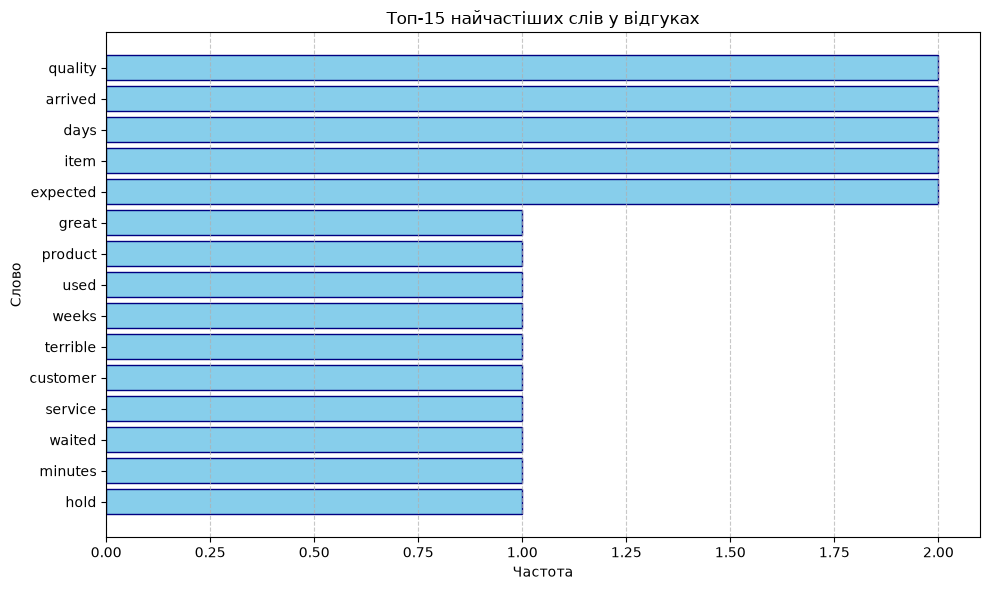

In [7]:
import matplotlib.pyplot as plt

all_filtered_tokens = [token for tokens_list in df['filtered_tokens'] for token in tokens_list]

word_counts = Counter(all_filtered_tokens)

top_15 = word_counts.most_common(15)

markdown_table = "| Слово | Частота |\n| :--- | :--- |\n"
for word, count in top_15:
    markdown_table += f"| {word} | {count} |\n"

print("Топ-15 найчастіших слів:")
display(Markdown(markdown_table))

words = [item[0] for item in top_15]
counts = [item[1] for item in top_15]

words.reverse()
counts.reverse()

plt.figure(figsize=(10, 6))
plt.barh(words, counts, color='skyblue', edgecolor='navy')

plt.xlabel('Частота')
plt.ylabel('Слово')
plt.title('Топ-15 найчастіших слів у відгуках')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()

plt.savefig('feedback_word_freq.png', dpi=300, bbox_inches='tight')

plt.show()

## завдання 4

In [8]:
all_bigrams = []
for tokens_list in df['filtered_tokens']:
    review_bigrams = [" ".join(bigram) for bigram in nltk.bigrams(tokens_list)]
    all_bigrams.extend(review_bigrams)

bigram_counts = Counter(all_bigrams)

bigrams_df = pd.DataFrame(bigram_counts.most_common(), columns=["Біграма", "Частота"])

print("Топ-10 найчастіших біграм:")
display(bigrams_df.head(10))

bigrams_df.to_csv("feedback_bigrams.csv", index=False, encoding="utf-8")

Топ-10 найчастіших біграм:


,Біграма,Частота
0,great product,1
1,product used,1
2,used weeks,1
3,weeks quality,1
4,terrible customer,1
5,customer service,1
6,service waited,1
7,waited minutes,1
8,minutes hold,1
9,delivery fast,1
